In [2]:
pip install pandas plotly

Note: you may need to restart the kernel to use updated packages.


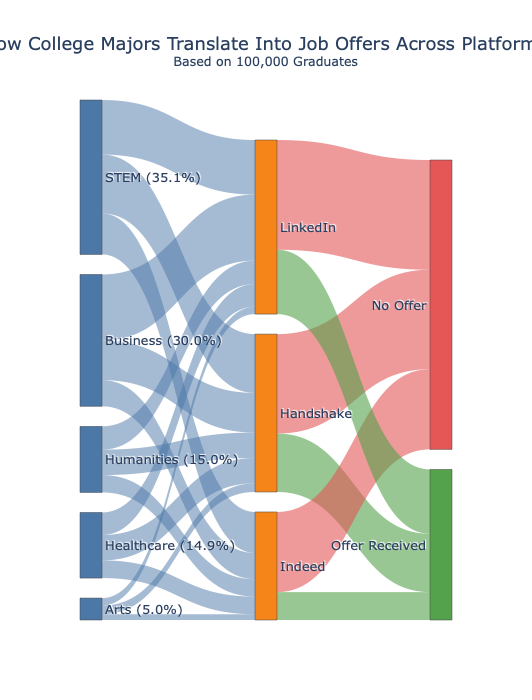

In [5]:
import pandas as pd
import plotly.graph_objects as go

# Load data
df = pd.read_csv("job_search_platform_efficacy_100k.csv")

df = df[["Major_Category", "Primary_Search_Platform", "Offer_Received"]].dropna()

# Clean offer column
def clean_offer(x):
    return "Offer Received" if str(x).lower() in ["1", "true", "yes"] else "No Offer"

df["Offer_Status"] = df["Offer_Received"].apply(clean_offer)

# -----------------------------
# Reduce clutter (top majors)
# -----------------------------
top_majors = df["Major_Category"].value_counts().nlargest(5).index
df["Major_Grouped"] = df["Major_Category"].where(df["Major_Category"].isin(top_majors), "Other")

# -----------------------------
# Create flows
# -----------------------------
stage1 = df.groupby(["Major_Grouped", "Primary_Search_Platform"]).size().reset_index(name="Count")
stage2 = df.groupby(["Primary_Search_Platform", "Offer_Status"]).size().reset_index(name="Count")

total = len(df)

# -----------------------------
# Create labels with %
# -----------------------------
major_counts = df["Major_Grouped"].value_counts()
platform_counts = df["Primary_Search_Platform"].value_counts()
offer_counts = df["Offer_Status"].value_counts()

major_nodes = [
    f"{m} ({round(100*major_counts[m]/total,1)}%)"
    for m in major_counts.index
]

platform_nodes = [
    f"{p} ({round(100*platform_counts[p]/total,1)}%)"
    for p in sorted(platform_counts.index)
]

offer_nodes = [
    f"{o} ({round(100*offer_counts[o]/total,1)}%)"
    for o in ["Offer Received", "No Offer"]
]



labels = major_nodes + platform_nodes + offer_nodes

# Mapping
label_to_index = {label: i for i, label in enumerate(labels)}

# Helper mapping
major_map = dict(zip(major_counts.index, major_nodes))

platform_map = dict(zip(sorted(platform_counts.index), platform_nodes))
offer_map = dict(zip(["Offer Received", "No Offer"], offer_nodes))

# -----------------------------
# Build links
# -----------------------------
sources, targets, values, link_colors = [], [], [], []

# Colors
major_color = "#4C78A8"
platform_color = "#F58518"
offer_green = "#54A24B"
offer_red = "#E45756"

# Stage 1
for _, row in stage1.iterrows():
    sources.append(label_to_index[major_map[row["Major_Grouped"]]])
    targets.append(label_to_index[row["Primary_Search_Platform"]])
    values.append(row["Count"])
    link_colors.append("rgba(76,120,168,0.5)")  # blue transparent

# Stage 2
for _, row in stage2.iterrows():
    sources.append(label_to_index[row["Primary_Search_Platform"]])
    targets.append(label_to_index[row["Offer_Status"]])
    values.append(row["Count"])
    
    if row["Offer_Status"] == "Offer Received":
        link_colors.append("rgba(84,162,75,0.6)")  # green
    else:
        link_colors.append("rgba(228,87,86,0.6)")  # red

# -----------------------------
# Node colors
# -----------------------------
node_colors = (
    [major_color]*len(major_nodes) +
    [platform_color]*len(platform_nodes) +
    [offer_green, offer_red]
)

# -----------------------------
# Plot
# -----------------------------
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=20,
        thickness=22,
        label=labels,
        color=node_colors
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color=link_colors
    )
)])

fig.update_layout(
    title={
        "text": "How College Majors Translate Into Job Offers Across Platforms<br><sup>Based on 100,000 Graduates</sup>",
        "x": 0.5
    },
    font_size=13,
    width=1200,
    height=700
)

fig.show()

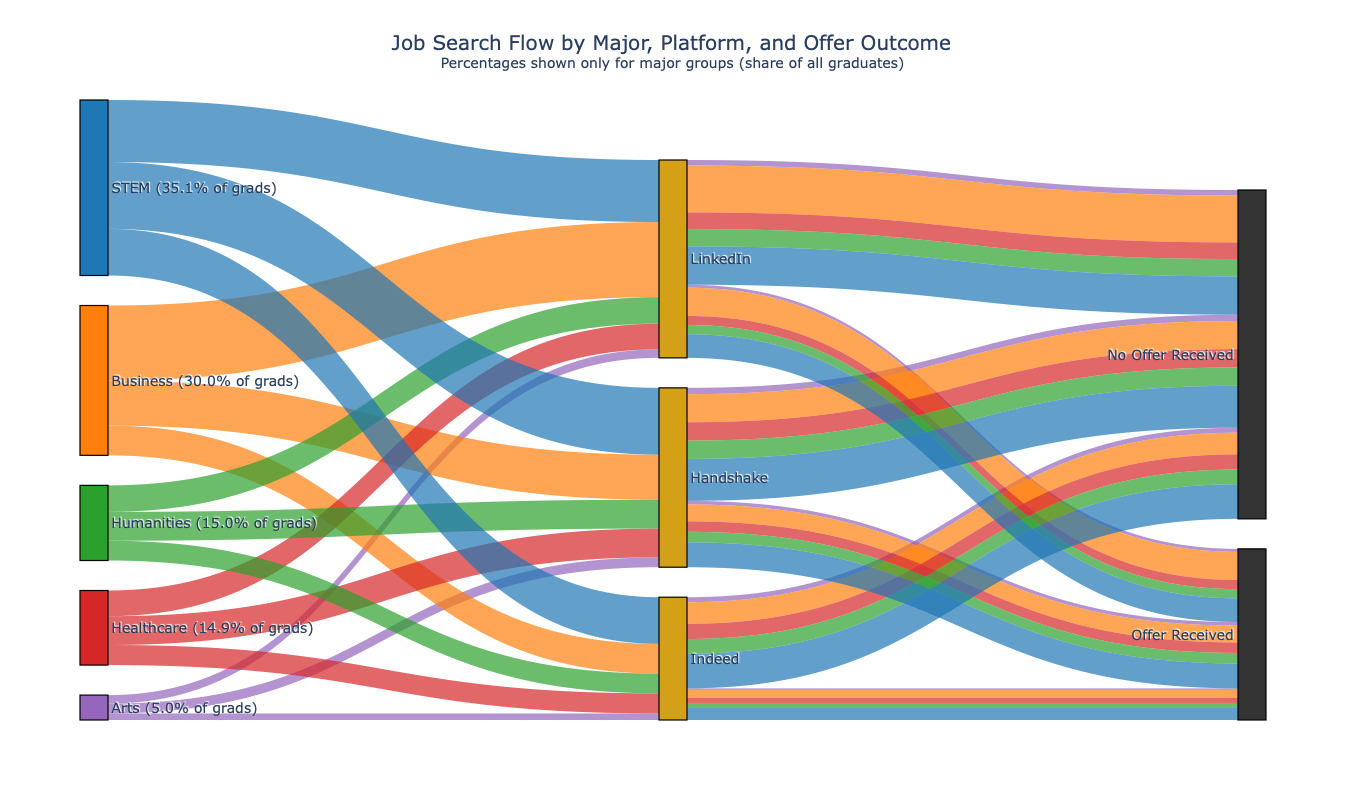

In [6]:
import pandas as pd
import plotly.graph_objects as go

# -----------------------------
# 1. Load data
# -----------------------------
df = pd.read_csv("job_search_platform_efficacy_100k.csv")

df = df[["Major_Category", "Primary_Search_Platform", "Offer_Received"]].dropna()

df["Offer_Status"] = df["Offer_Received"].map({
    1: "Offer Received",
    0: "No Offer Received"
})

# -----------------------------
# 2. Top 5 majors
# -----------------------------
top_majors = df["Major_Category"].value_counts().nlargest(5).index
df["Major_Grouped"] = df["Major_Category"].where(
    df["Major_Category"].isin(top_majors),
    "Other"
)

# -----------------------------
# 3. Flow counts
# -----------------------------
stage1 = df.groupby(["Major_Grouped", "Primary_Search_Platform"]).size().reset_index(name="Count")

stage2 = df.groupby(["Major_Grouped", "Primary_Search_Platform", "Offer_Status"]).size().reset_index(name="Count")

total = len(df)

# -----------------------------
# 4. Labels
# -----------------------------
major_counts = df["Major_Grouped"].value_counts()
major_order = major_counts.index.tolist()

platform_order = ["LinkedIn", "Handshake", "Indeed"]
offer_order = ["Offer Received", "No Offer Received"]

major_nodes = [
    f"{m} ({round(100 * major_counts[m] / total, 1)}% of grads)"
    for m in major_order
]

platform_nodes = platform_order
offer_nodes = offer_order

labels = major_nodes + platform_nodes + offer_nodes
label_to_index = {label: i for i, label in enumerate(labels)}

major_map = dict(zip(major_order, major_nodes))
platform_map = dict(zip(platform_order, platform_nodes))
offer_map = dict(zip(offer_order, offer_nodes))

# -----------------------------
# 5. STRONGER COLORS
# -----------------------------
major_colors = {
    "STEM": "#1f77b4",        # strong blue
    "Business": "#ff7f0e",    # strong orange
    "Humanities": "#2ca02c",  # strong green
    "Healthcare": "#d62728",  # strong red
    "Arts": "#9467bd",        # strong purple
    "Other": "#7f7f7f"
}

platform_color = "#d4a017"   # bold gold
offer_node_color = "#333333" # dark neutral

# Convert hex → rgba with HIGH opacity
def hex_to_rgba(hex_color, alpha=0.75):
    hex_color = hex_color.lstrip("#")
    r = int(hex_color[0:2], 16)
    g = int(hex_color[2:4], 16)
    b = int(hex_color[4:6], 16)
    return f"rgba({r},{g},{b},{alpha})"

# -----------------------------
# 6. Build links
# -----------------------------
sources, targets, values, link_colors = [], [], [], []

# Major → Platform
for _, row in stage1.iterrows():
    major = row["Major_Grouped"]

    sources.append(label_to_index[major_map[major]])
    targets.append(label_to_index[platform_map[row["Primary_Search_Platform"]]])
    values.append(row["Count"])

    link_colors.append(hex_to_rgba(major_colors.get(major, "#999999"), 0.7))

# Platform → Outcome
for _, row in stage2.iterrows():
    major = row["Major_Grouped"]

    sources.append(label_to_index[platform_map[row["Primary_Search_Platform"]]])
    targets.append(label_to_index[offer_map[row["Offer_Status"]]])
    values.append(row["Count"])

    link_colors.append(hex_to_rgba(major_colors.get(major, "#999999"), 0.7))

# -----------------------------
# 7. Node colors
# -----------------------------
node_colors = (
    [major_colors.get(m, "#999999") for m in major_order] +
    [platform_color] * len(platform_order) +
    [offer_node_color] * len(offer_order)
)

# -----------------------------
# 8. Sankey chart
# -----------------------------
fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node=dict(
        pad=30,                 # MORE spacing between nodes
        thickness=28,           # thicker nodes
        line=dict(color="black", width=1.2),  # stronger borders
        label=labels,
        color=node_colors
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color=link_colors
    )
)])

fig.update_layout(
    title={
        "text": (
            "Job Search Flow by Major, Platform, and Offer Outcome"
            "<br><sup>Percentages shown only for major groups (share of all graduates)</sup>"
        ),
        "x": 0.5
    },
    font_size=14,
    width=1400,
    height=800
)

fig.show()